<h1>Section 3 – Unsupervised learning – clustering</h1>
In this unsupervised learning task, the objective is to cluster Reddit comments based on the words used
within the comments in them. The aim is to identify patterns and group comments with similar words
together.

<h2>Kmeans</h2>

In [1]:
!pip install nltk
!pip install WordCloud

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pickle

from scipy.sparse import csr_matrix

from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
#from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, HDBSCAN
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score

from wordcloud import WordCloud

from itertools import product

In [3]:
# data=pd.read_csv("data_unsupervised.csv", encoding="utf8")

# data['body'] = data['body'].str.lower()#to lowercase
# data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
# data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace
# data = data[data['body'].str.strip().astype(bool)]#remove empty comments
# data=data.drop_duplicates()#remove duplicates

# from langdetect import detect, DetectorFactory
# DetectorFactory.seed = 0  # rende i risultati stabili

# # Assicuriamoci che 'body' sia stringa
# data['body'] = data['body'].fillna('').astype(str)

# # Applichiamo il rilevamento lingua gestendo errori e testi vuoti
# langs = []
# for text in data['body']:
#     # if not text.strip():  # se la riga del commento è vuota
#     #     langs.append("empty")
#     # else:
#     try:
#         langs.append(detect(text))
#     except:
#         langs.append("error")

# data['language'] = langs

# # Conta quante frasi ci sono per ciascuna lingua
# counts = data['language'].value_counts()
# print(counts)

# data.to_csv("data_unsupervised_lang.csv", index=False)

In [4]:
#print(data[data['language'] == 'error'])


In [5]:
data=pd.read_csv("data_unsupervised_lang.csv", encoding="utf8")
data = data[data['language'] == 'en'] #keep only English comments

data['body'] = data['body'].str.lower()#to lowercase
data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace

#data = data[~(data['body'].str.len() < 10)] #drop comments with less than 10 characters
#data = data[~(data['body'].str.len() > 500)] #drop comments with more than 500 characters

data = data[data['body'].str.strip().astype(bool)]
data=data.drop_duplicates()
lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

word_counts = data['body'].str.split().explode().value_counts()    
words_once = set(word_counts[word_counts == 1].index)#words that appear only once
most_freq_words = set(word_counts.nlargest(100).index)#most common words treated as stop words
remove_words = words_once | most_freq_words

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments
data = data.drop_duplicates(subset=['body'])
vectorizer = CountVectorizer()
vectorized_data = vectorizer.fit_transform(data['body'])

In [ ]:
n_components=min(1000, vectorized_data.shape[1])
svd = TruncatedSVD(n_components=n_components)
X = svd.fit_transform(vectorized_data)
X=csr_matrix(X)
print("Explained variance by SVD:", svd.explained_variance_ratio_.sum())

plt.figure(figsize=(8, 5))
plt.plot(range(1, n_components+1), svd.explained_variance_ratio_.cumsum(), marker='o')
plt.xlabel('Number of Features (n_components)')
plt.ylabel('Cumulative Explained Variance')
plt.title('TruncatedSVD: Explained Variance vs Number of Features')
plt.grid(True)
plt.show()

In [ ]:
# n_components=400
# svd = TruncatedSVD(n_components=n_components)
# X = svd.fit_transform(vectorized_data)
# print("Explained variance by SVD:", svd.explained_variance_ratio_.sum())

# X = MaxAbsScaler().fit_transform(X)
# X=X*5

Explained variance by SVD: 0.6331969317919928


silhouette score computed:  0.7671060176514634
silhouette score computed:  0.6512833463367292
silhouette score computed:  0.6948092550514472
silhouette score computed:  0.5734857074270996
silhouette score computed:  0.21082244206233475
silhouette score computed:  0.7566911411949178
silhouette score computed:  0.5012411276143329
silhouette score computed:  0.24885035360203805
silhouette score computed:  0.24331847506066132
silhouette score computed:  0.3209389224266139
silhouette score computed:  0.16873690024985127
silhouette score computed:  0.10821521475647289
silhouette score computed:  0.1607451364308528
silhouette score computed:  0.16491549692720828
silhouette score computed:  0.14526049985546804


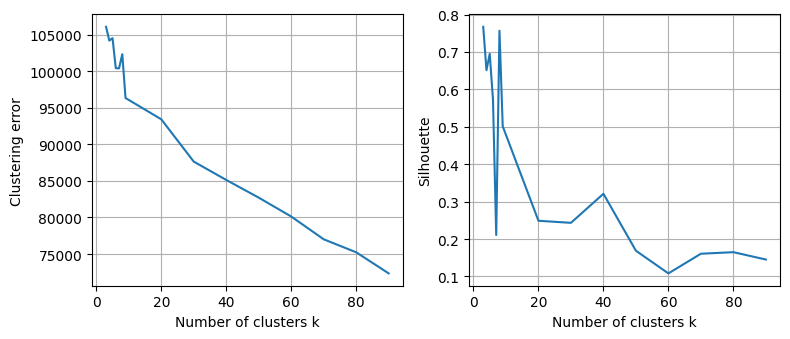

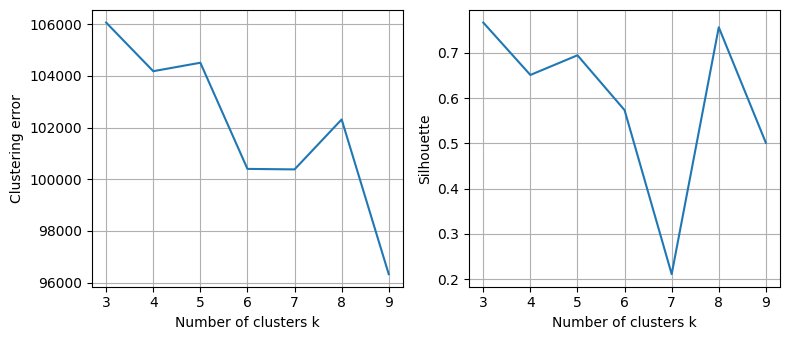

In [ ]:
n_clusters=2
kmeans = KMeans(
    n_clusters, #will be choosen later
    init='random', #centroids are initialized randomly TOO SLOW
    #init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=42, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=300,
    tol=1e-2
    )
clustering_results = []

k_values=pd.concat([pd.Series(range(3, 10, 1)),pd.Series(range(20, 100, 10))])
for k in k_values:
    clustering_results.append(KMeans(n_clusters=k).fit(X))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

n_sample=10000
silhouetteScores = []
for result in clustering_results:
    try:
        silhouetteScores.append(silhouette_score(X, result.labels_, sample_size=n_sample))
        print("silhouette score computed: ", silhouetteScores[-1])
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

# Plotting the results
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))
axs[0].plot(
    [k for k in k_values], 
    [result.inertia_ for result in clustering_results]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()
axs[1].plot(
    [k for k in k_values], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.tight_layout()
plt.show()


# Plotting the results again but only for k up to 10

fig, axs = plt.subplots(1,2, figsize=(8, 3.5))
axs[0].plot(
    [k for k in k_values[:7]], 
    [result.inertia_ for result in clustering_results[:7]]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()
axs[1].plot(
    [k for k in k_values[:7]], 
    [s for s in silhouetteScores[:7]]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.tight_layout()
plt.show()

In [9]:
numberOfChoosenClusters=8
indexOfChoosenCluster=k_values[k_values==numberOfChoosenClusters].index[0]

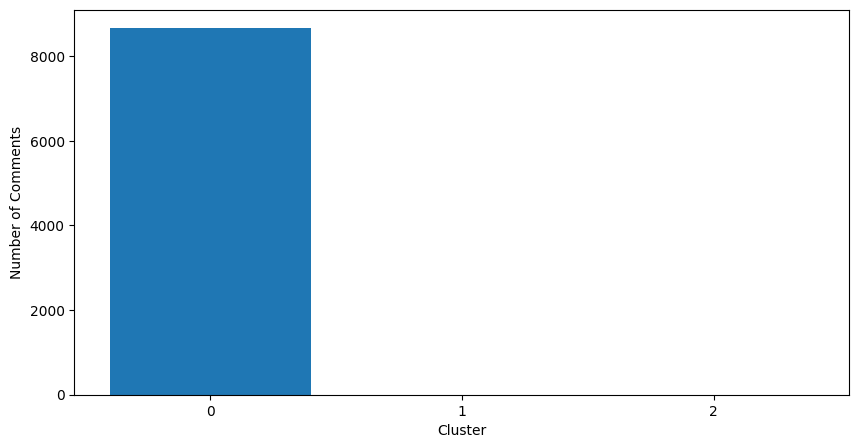

Cluster sizes: 0    8666
2       1
1       1
Name: count, dtype: int64


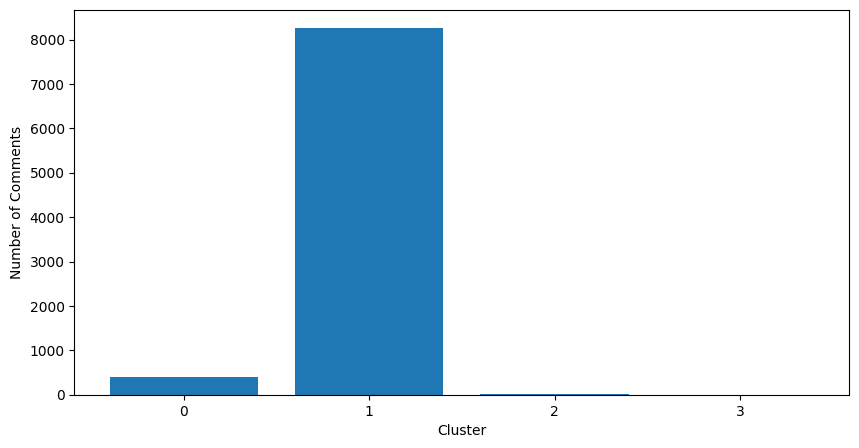

Cluster sizes: 1    8258
0     388
2      21
3       1
Name: count, dtype: int64


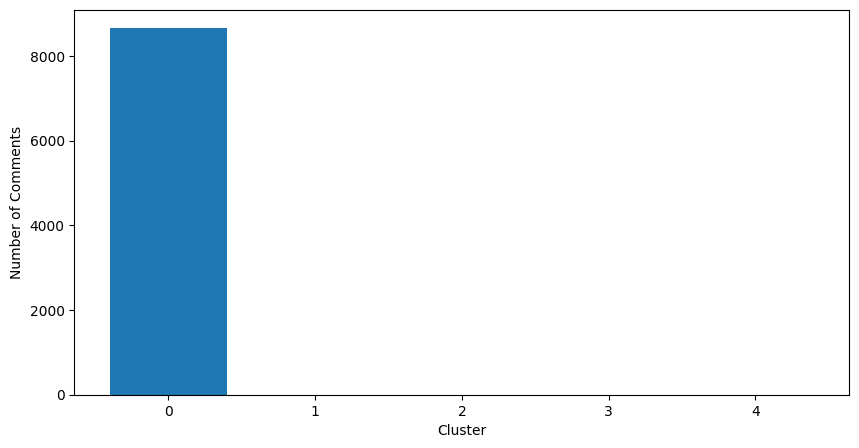

Cluster sizes: 0    8660
4       5
1       1
3       1
2       1
Name: count, dtype: int64


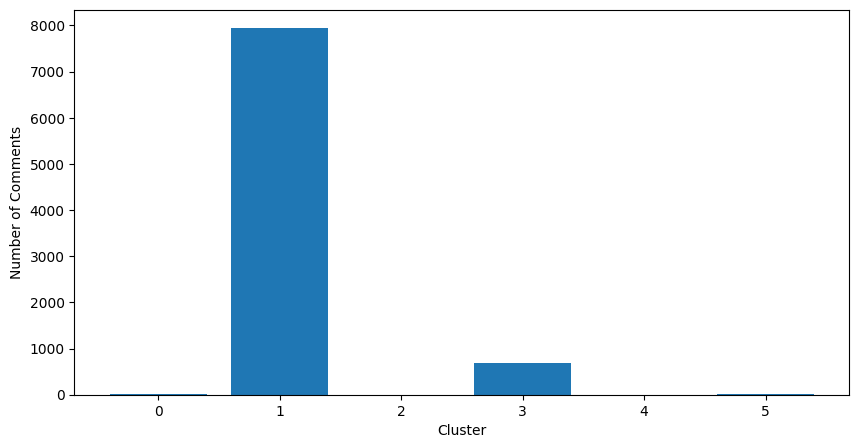

Cluster sizes: 1    7943
3     683
0      20
5      20
4       1
2       1
Name: count, dtype: int64


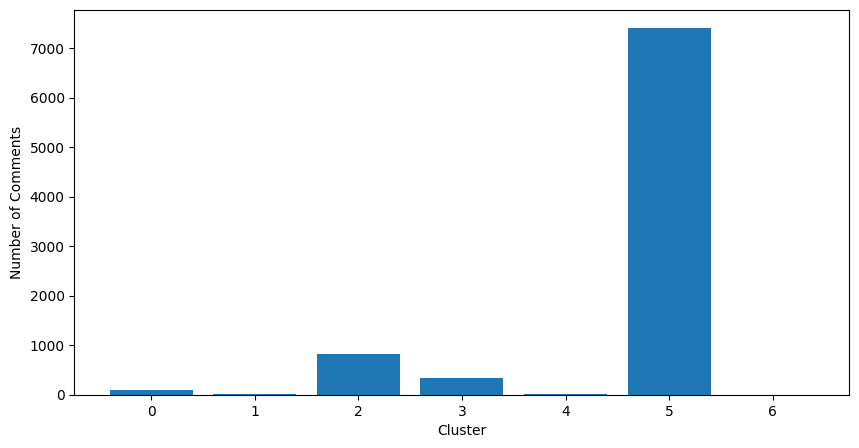

Cluster sizes: 5    7402
2     819
3     329
0      86
1      21
4      10
6       1
Name: count, dtype: int64


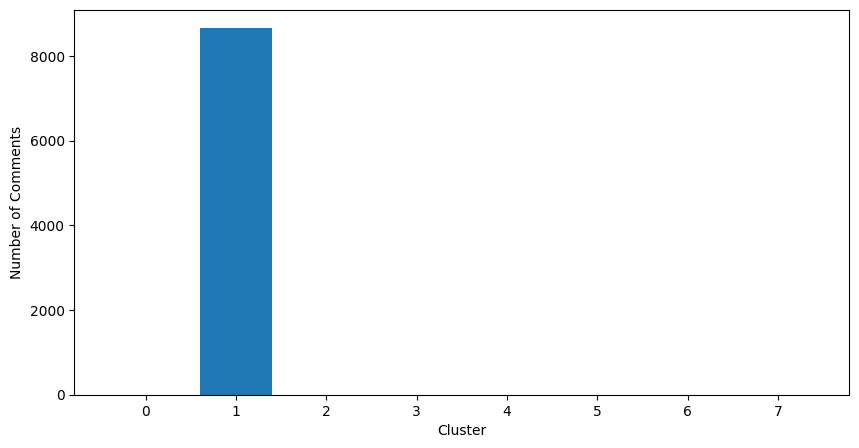

Cluster sizes: 1    8660
0       2
2       1
7       1
5       1
6       1
3       1
4       1
Name: count, dtype: int64


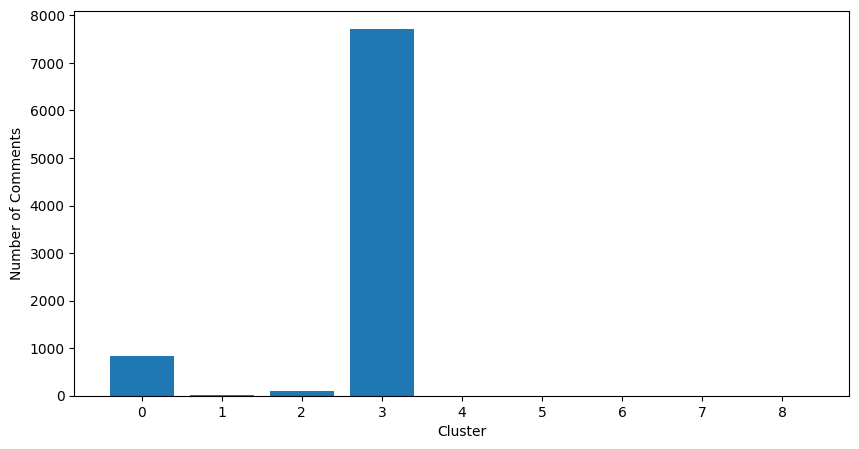

Cluster sizes: 3    7712
0     840
2      92
1      19
7       1
5       1
6       1
8       1
4       1
Name: count, dtype: int64


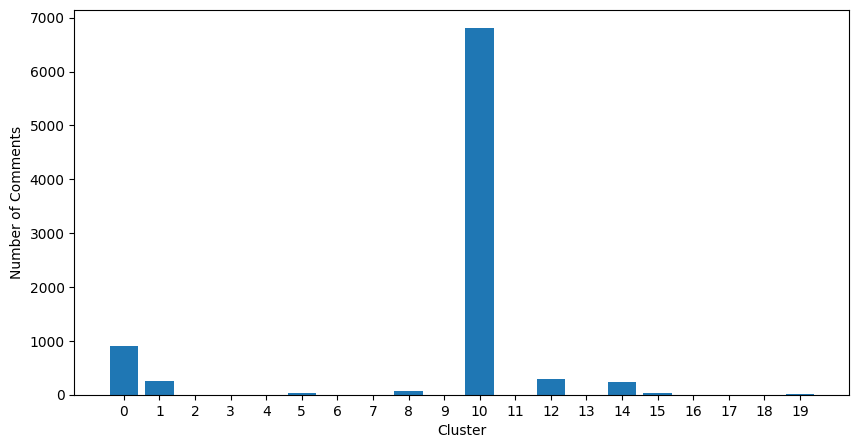

Cluster sizes: 10    6808
0      909
12     295
1      251
14     229
8       76
5       34
15      30
19      19
17       3
13       2
16       2
6        2
11       2
18       1
3        1
4        1
2        1
9        1
7        1
Name: count, dtype: int64


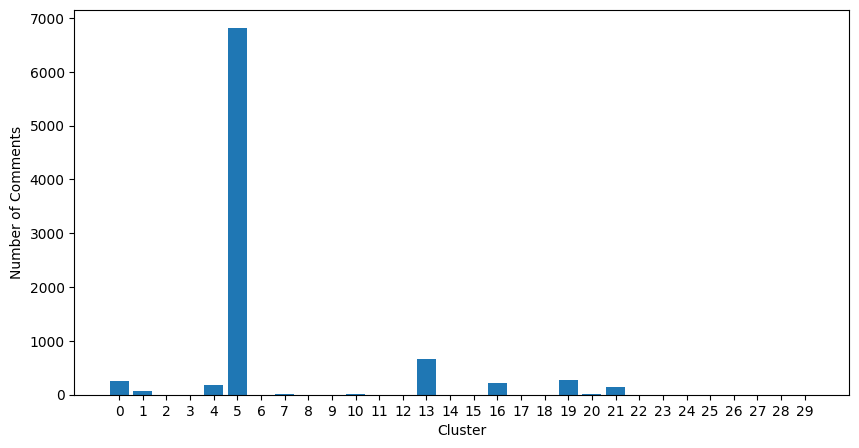

Cluster sizes: 5     6812
13     656
19     267
0      261
16     222
4      189
21     135
1       60
10      19
7       17
20      10
27       2
23       1
25       1
9        1
22       1
2        1
26       1
6        1
24       1
12       1
3        1
29       1
14       1
18       1
15       1
11       1
17       1
8        1
28       1
Name: count, dtype: int64


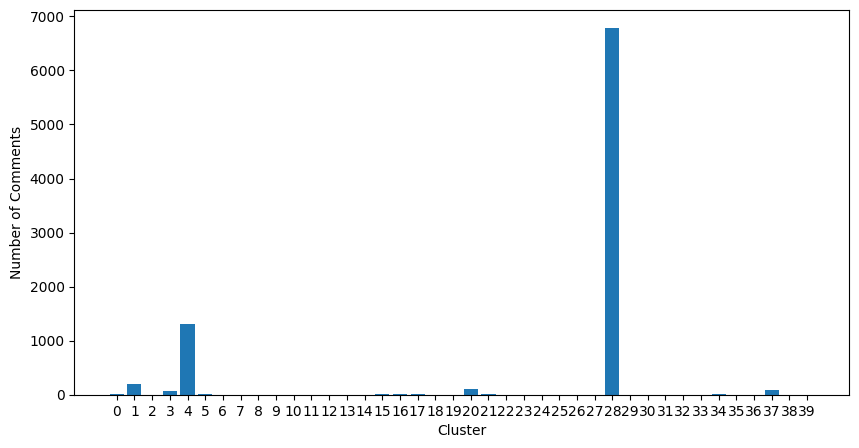

Cluster sizes: 28    6784
4     1303
1      196
20     102
37      92
3       62
21      22
17      22
5       19
0       14
34      11
16       8
15       5
12       2
18       1
11       1
39       1
13       1
24       1
30       1
22       1
26       1
27       1
36       1
8        1
35       1
9        1
29       1
25       1
2        1
10       1
19       1
32       1
38       1
14       1
33       1
6        1
31       1
7        1
23       1
Name: count, dtype: int64


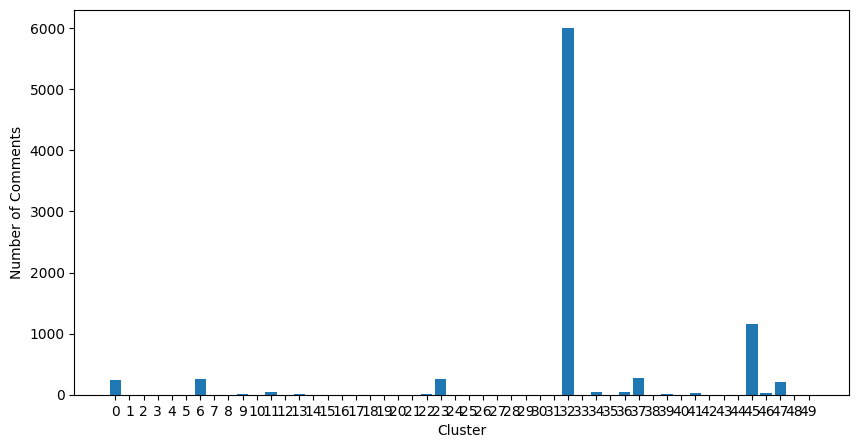

Cluster sizes: 32    6000
45    1158
37     268
23     264
6      259
0      239
47     215
36      51
34      44
11      39
41      24
46      24
13      18
39      11
22      10
9        7
10       3
16       2
7        1
14       1
44       1
8        1
48       1
26       1
2        1
30       1
15       1
5        1
33       1
20       1
18       1
27       1
35       1
38       1
49       1
29       1
42       1
43       1
40       1
4        1
12       1
25       1
21       1
3        1
24       1
28       1
17       1
31       1
19       1
1        1
Name: count, dtype: int64


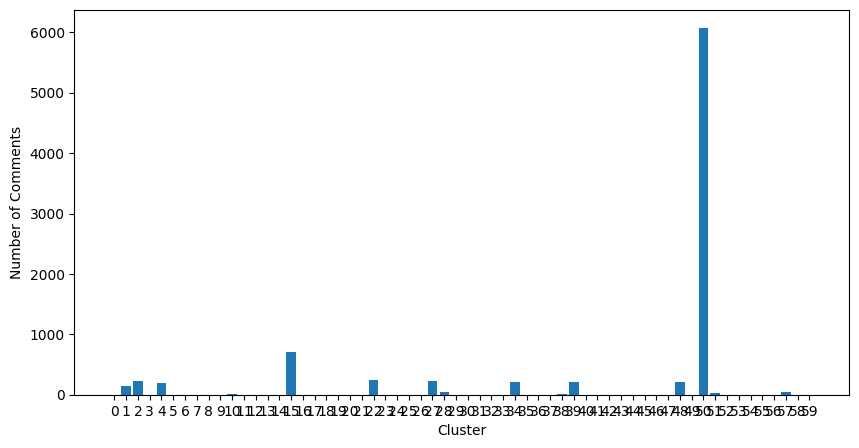

Cluster sizes: 50    6070
15     714
22     249
27     232
2      231
34     214
39     211
48     205
4      198
1      140
57      53
28      46
51      21
38      18
10      16
6        3
53       2
58       2
54       2
3        1
21       1
25       1
32       1
0        1
55       1
17       1
11       1
14       1
56       1
16       1
24       1
43       1
7        1
42       1
40       1
19       1
30       1
45       1
46       1
5        1
12       1
23       1
35       1
52       1
44       1
49       1
26       1
59       1
31       1
18       1
8        1
37       1
41       1
13       1
20       1
47       1
9        1
36       1
33       1
29       1
Name: count, dtype: int64


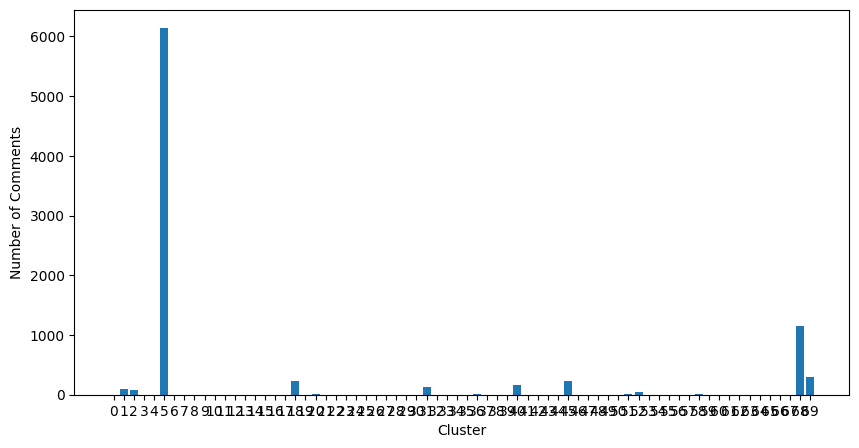

Cluster sizes: 5     6141
68    1158
69     305
45     237
18     235
      ... 
59       1
27       1
0        1
35       1
42       1
Name: count, Length: 70, dtype: int64


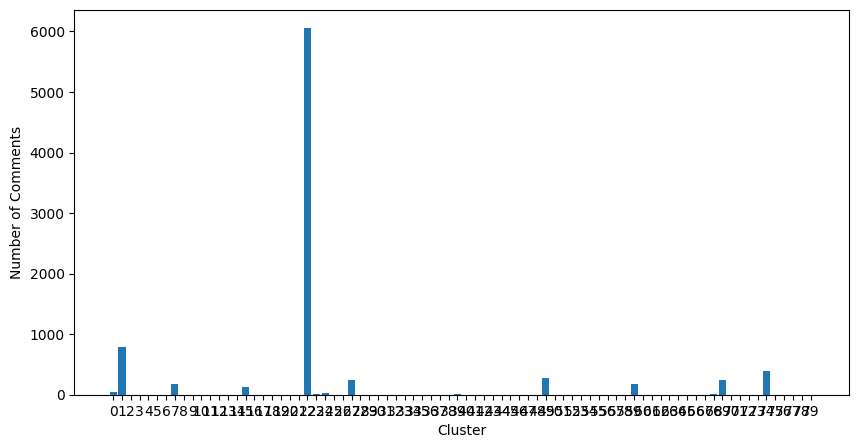

Cluster sizes: 22    6056
1      792
74     397
49     272
69     243
      ... 
8        1
51       1
11       1
77       1
53       1
Name: count, Length: 80, dtype: int64


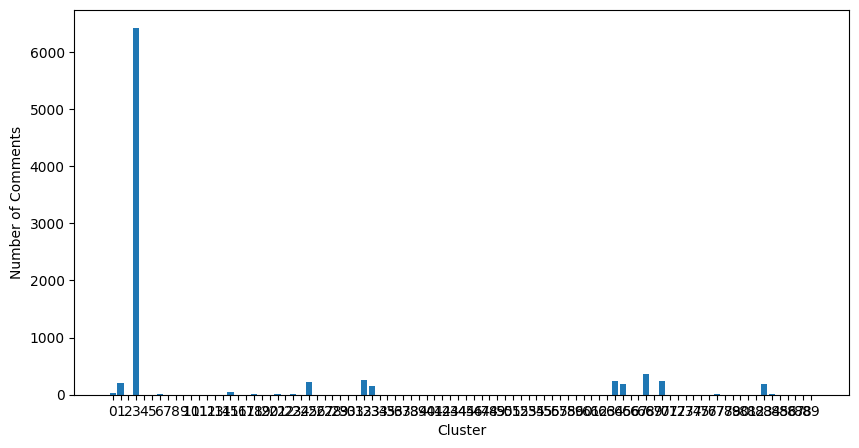

Cluster sizes: 3     6417
68     370
32     262
64     243
70     238
      ... 
29       1
69       1
46       1
58       1
56       1
Name: count, Length: 90, dtype: int64


In [10]:
#Plot the number of comments for each cluster
for i in clustering_results:
    cluster_sizes = pd.Series(i.labels_).value_counts()
    plt.figure(figsize=(10, 5))
    plt.bar(cluster_sizes.index, cluster_sizes.values)
    #plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Comments")
    plt.xticks(cluster_sizes.index)
    plt.show()
    print("Cluster sizes:", cluster_sizes)

In [11]:
# with open("clustering_results.pkl", "rb") as f:
#     clustering_results = pickle.load(f)
# k_values=pd.concat([pd.Series(range(3, 10, 1)),pd.Series(range(20, 100, 10))])

<h2>Cluster analysis</h2>
<h3>User Distribution Analysis</h3>
Analyze how the users are distributed (each user can be assigned to more clusters because we
are clustering comments). Show the ECDF of number of clusters assigned to each user.

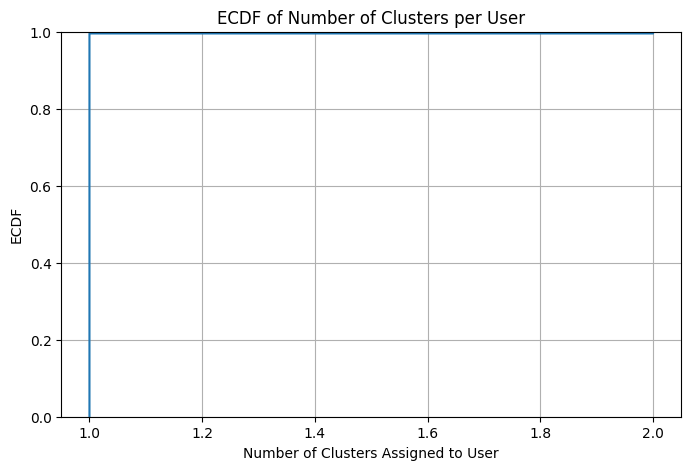

In [12]:
data["cluster"]= clustering_results[indexOfChoosenCluster].labels_
user_clusters = data.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

Use the first two components of the <del>PCA (found in Section 1.4)</del> Truncated SVD. Then visualize on these two dimensions to gain insights into their distribution and separability.

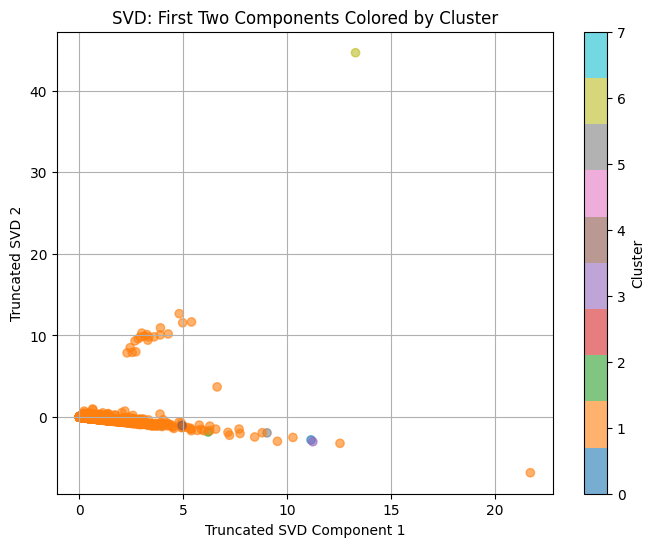

In [13]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 1')
plt.ylabel('Truncated SVD 2')
plt.title('SVD: First Two Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

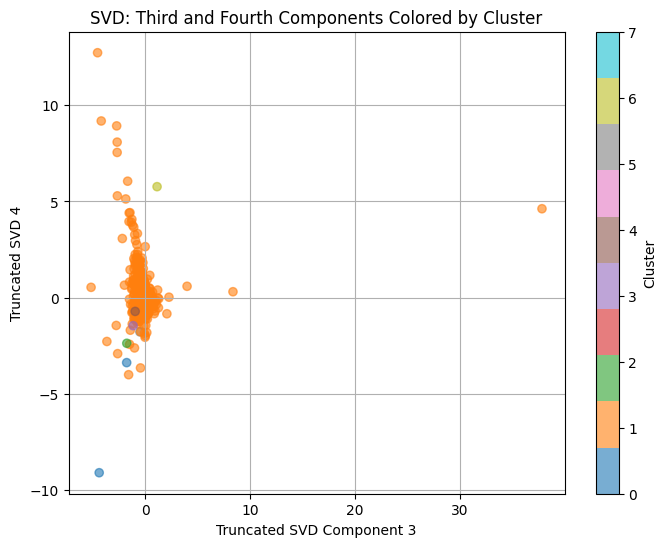

In [14]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 2], X[:, 3], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 3')
plt.ylabel('Truncated SVD 4')
plt.title('SVD: Third and Fourth Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

<h3>Cluster analysis</h3>
Analyze the characteristics of each cluster. This might involve examining the most frequent
words in each cluster (try word cloud). HINT: the most used words are not always the most
representative, for example word ‘the’ will be very popular in every cluster if you didn’t remove it from the dataset. Try to understand which are the most representative

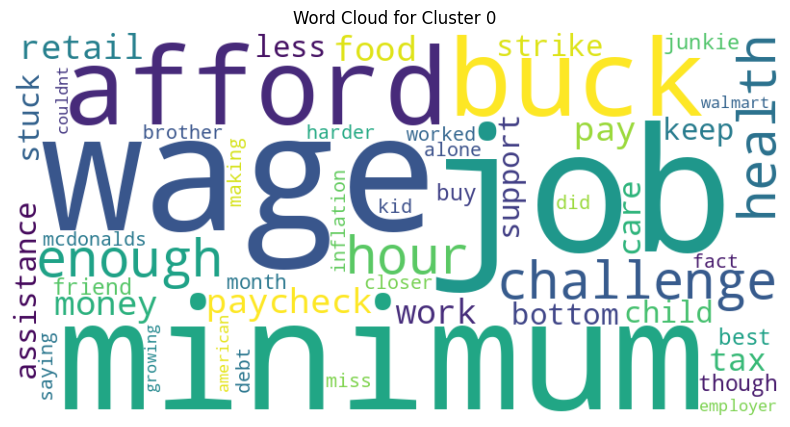

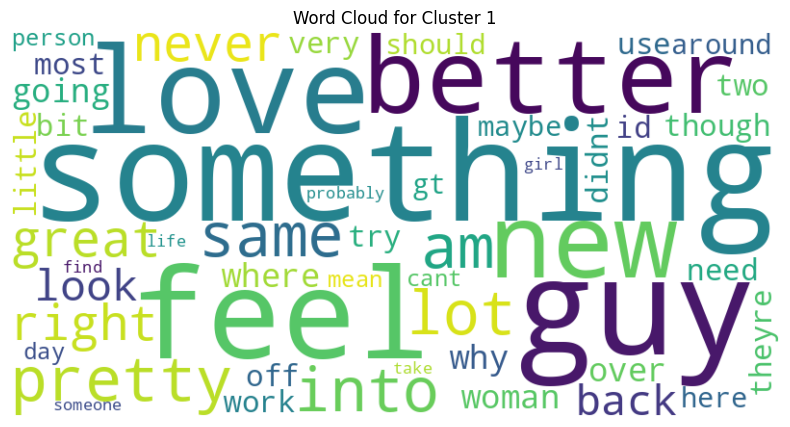

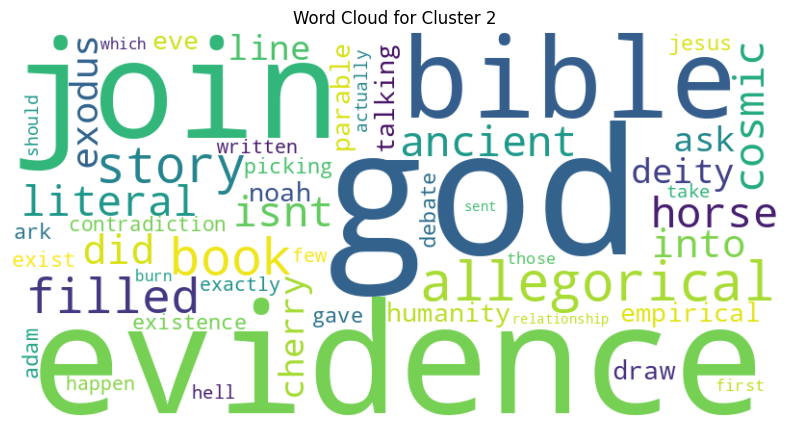

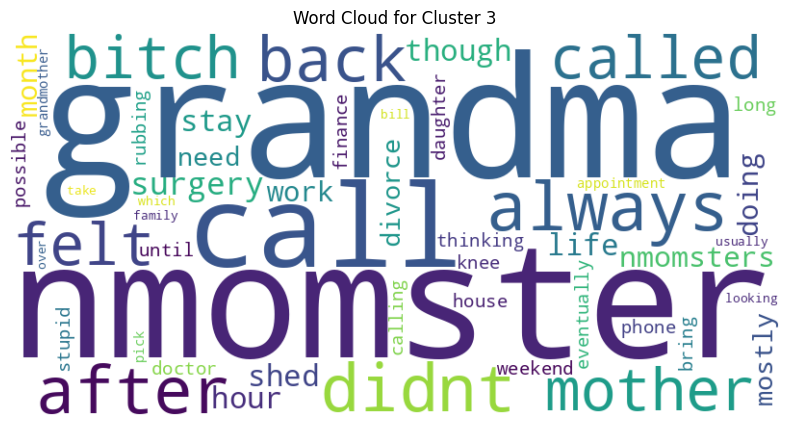

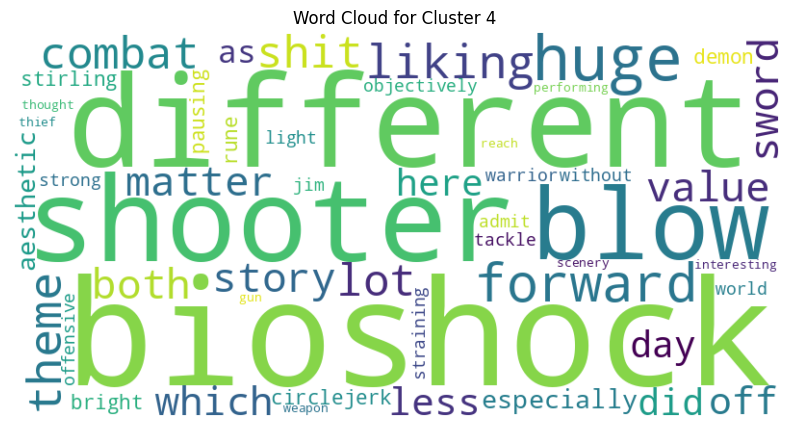

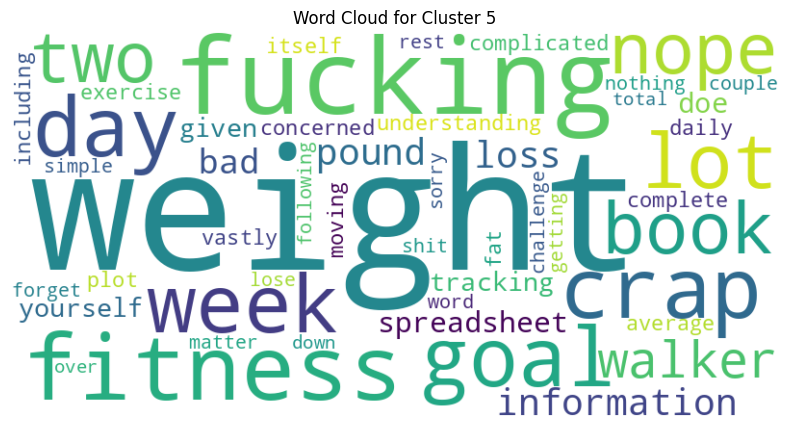

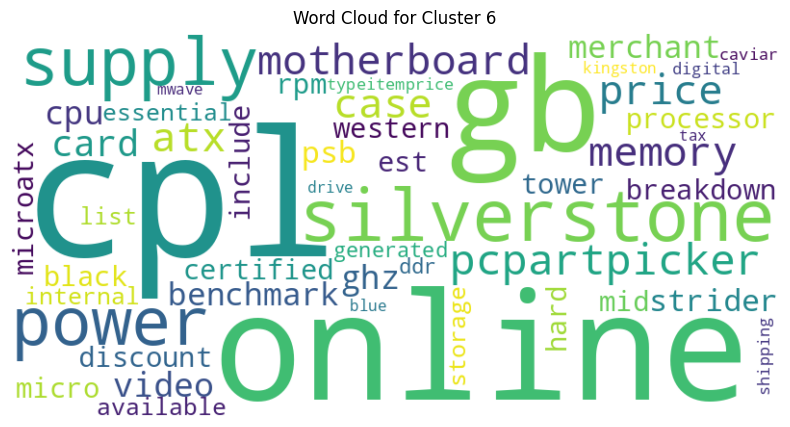

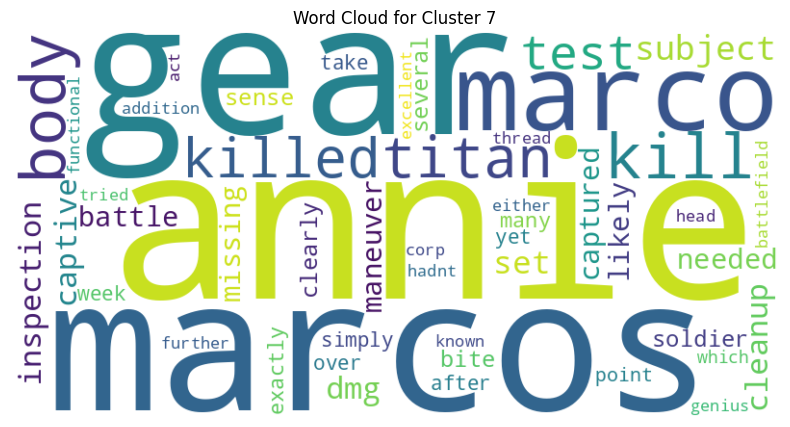

In [15]:
#Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
cluster_documents=data[['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
terms = tfidf_vectorizer.get_feature_names_out()

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in range(numberOfChoosenClusters):
    tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
    top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
    top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Cluster {cluster_num}')
    plt.show()

Finally, analyze and visualize how the subreddit are distributed among the found clusters. Are there pure clusters where only few related
subreddits end up?

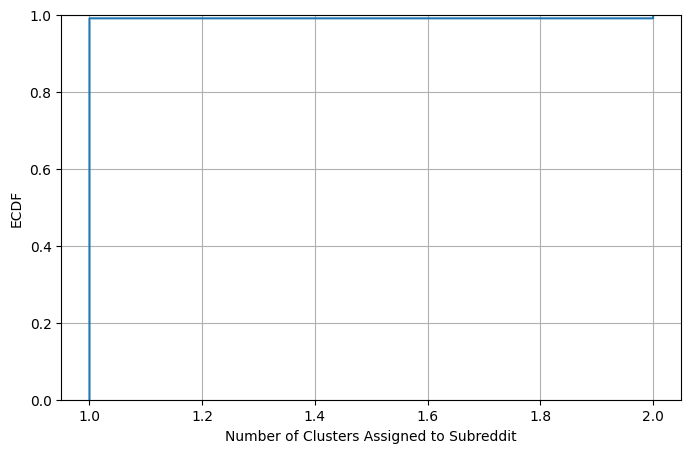

In [16]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 0 has 2 comments


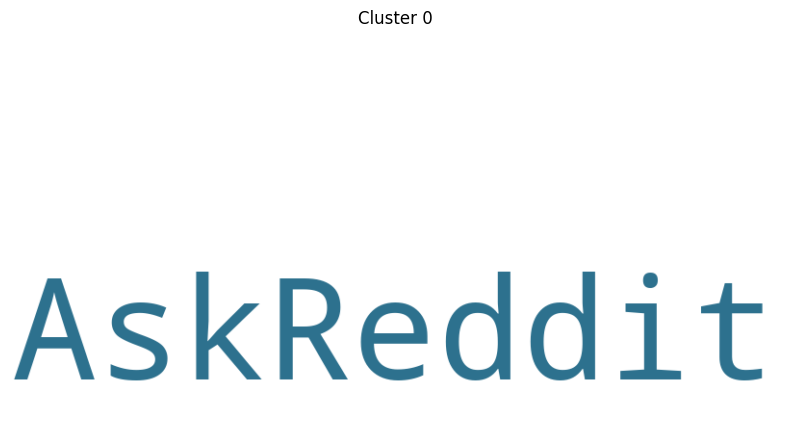

Cluster 1 has 8660 comments


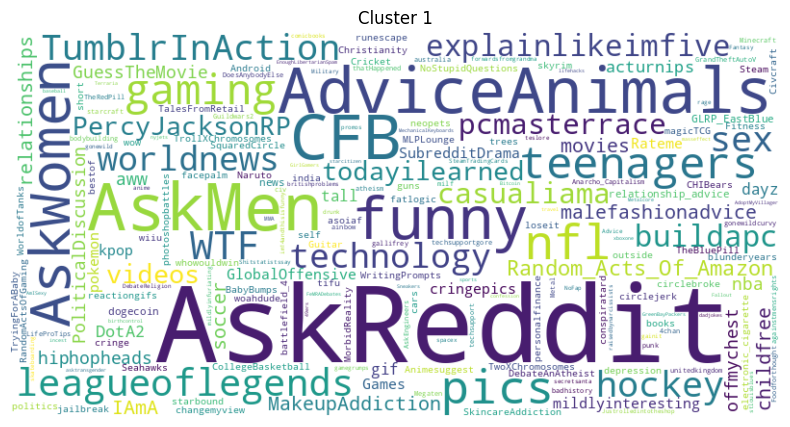

Cluster 2 has 1 comments


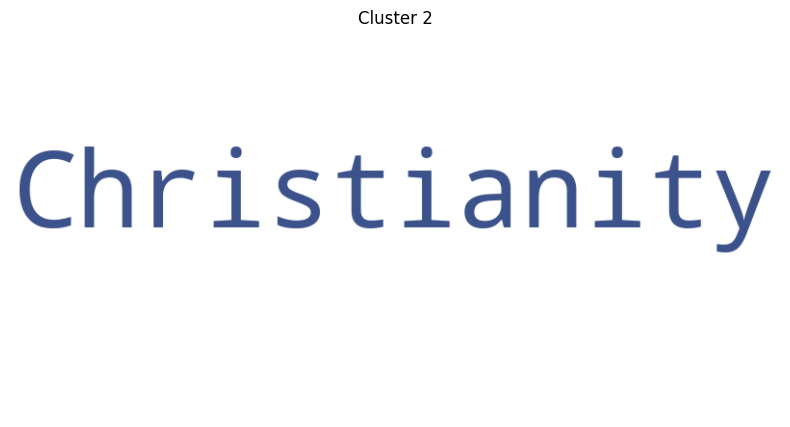

Cluster 3 has 1 comments


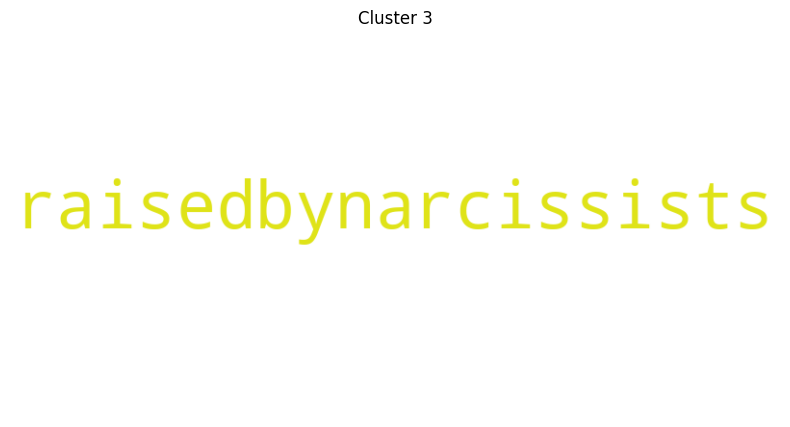

Cluster 4 has 1 comments


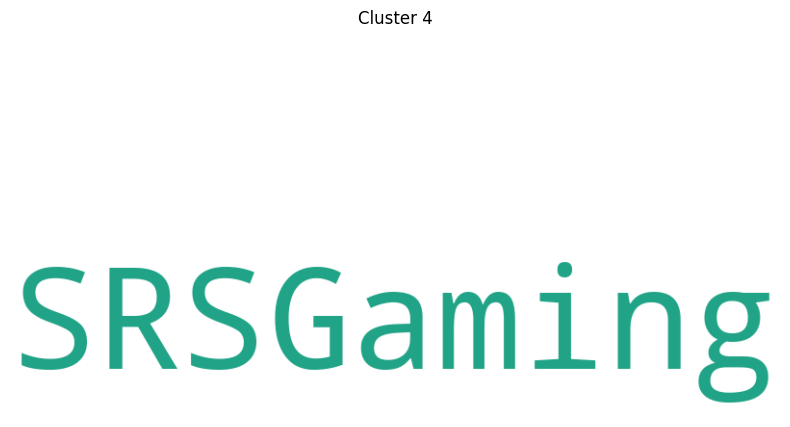

Cluster 5 has 1 comments


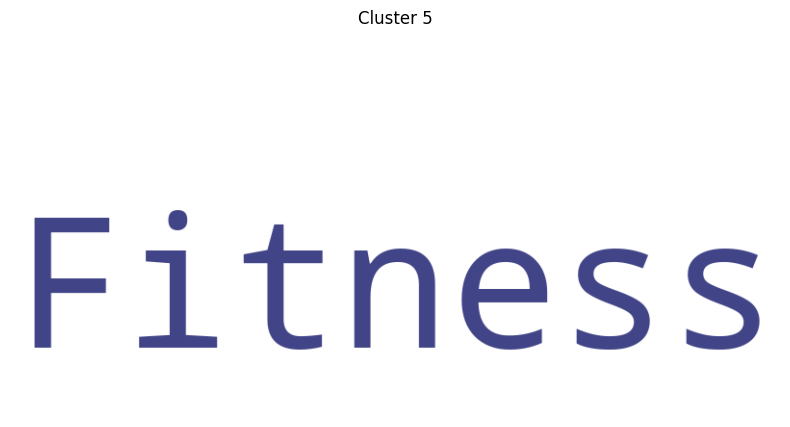

Cluster 6 has 1 comments


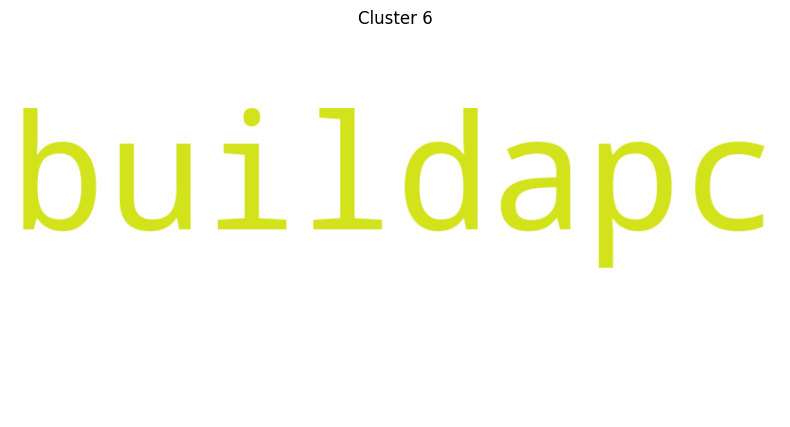

Cluster 7 has 1 comments


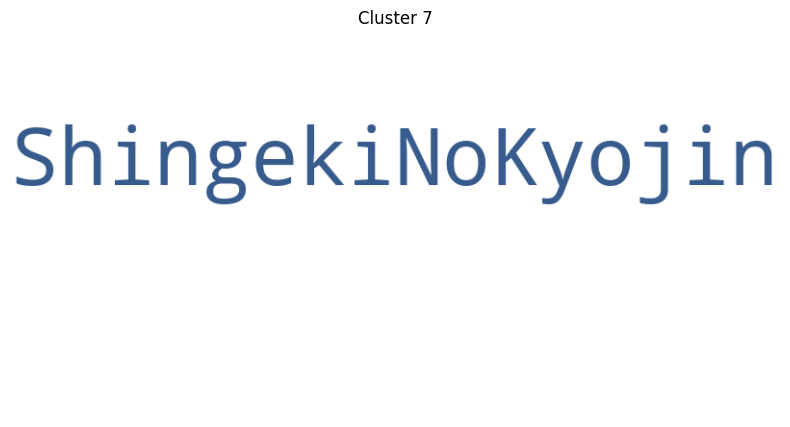

In [17]:
subredditsNames = []
for i in range(0, numberOfChoosenClusters):
    cluster_sizes = data['cluster'].value_counts()
    print(f"Cluster {i} has {cluster_sizes[i]} comments")
    subredditsNames.append(" ".join(data[data['cluster'] == i]['subreddit'].values))
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames[i])

    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {i}")
    plt.show()

Do clusters reflect subreddit division?

In [18]:
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: -3.444671648431496e-05
NMI: 0.0020626439442248904
AMI: 0.0002472258707328748


Since the results above for ARI,NMI and AMI are very low, we can try to cluster with nunmber of cluster equal to the number of subreddit and see how the number of clusters affects these values

In [19]:
kmeans= KMeans(
    n_clusters=len(data["subreddit"].unique()), #number of unique subreddits
    init='random',
    random_state=42,
    n_init='auto',
    max_iter=300,
    tol=1e-2
    )

data["cluster"]= kmeans.fit_predict(X)
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: 0.0044248079632648925
NMI: 0.4345934314280376
AMI: 0.021912898240655267


In [20]:
del data["cluster"], ami, nmi, ari, authors_with_multiple_comments, cluster_documents, cluster_num, cluster_sizes, clustering_results, k_values, axs,fig,indexOfChoosenCluster,numberOfChoosenClusters,n_sample,scatter,silhouetteScores,svd,top_indices,top_terms,tfidf_matrix,tfidf_scores,tfidf_vectorizer,vectorized_data,words_once,i,k,kmeans,n_clusters,result

In [21]:
# import pickle
# pickle.dump(data, open("data.pkl", "wb"))
# pickle.dump(X, open("X.pkl", "wb"))

In [22]:
# import pickle
# data = pickle.load(open("data.pkl", "rb"))
# X = pickle.load(open("X.pkl", "rb"))

<h2>HDBSCAN</h2>

In [23]:
#sampling
from sklearn.model_selection import train_test_split

# try:
#     X_sample, _, X_sample_authors, __ = train_test_split(X, stratify=data['author'], train_size=0.15, random_state=52)
#     print("Class distribution of train set")
#     print(X_sample_authors.value_counts())
#     print()
#     print("Class distribution of test set")
#     print(__.value_counts())
# except ValueError as e:
#     try:
#         print(f"Stratified split failed due to error: {e}")
#         X_sample, _, X_sample_authors, __ = train_test_split(X, stratify=data['subreddit'], train_size=0.15, random_state=52)
#         print("Class distribution of train set")
#         print(X_sample_authors.value_counts())
#         print()
#         print("Class distribution of test set")
#         print(__.value_counts())
#     except ValueError as e2:
#         print(f"Stratified split failed due to error: {e2}")

# filter out authors with only one comment
author_counts = data['author'].value_counts()
authors_with_multiple_comments = author_counts[author_counts > 1].index
filtered_data = data[data['author'].isin(authors_with_multiple_comments)]
X_filtered = X[data['author'].isin(authors_with_multiple_comments)]

_, X_sample, __ , X_sample_authors = train_test_split(
    X_filtered, 
    filtered_data['author'], 
    stratify=filtered_data['author'], 
    train_size=0.85, 
    random_state=52
)

# Append authors with only one comment back to the sample


X_sample = np.concatenate([X_sample, X[~data['author'].isin(authors_with_multiple_comments)]])
X_sample_authors = pd.concat([pd.Series(X_sample_authors), data.loc[~data['author'].isin(authors_with_multiple_comments), 'author']])

# print("Class distribution of train set")
# print(pd.Series(X_sample_authors).value_counts())
# print()
# print(pd.Series(__).value_counts())

ValueError: The test_size = 1127 should be greater or equal to the number of classes = 1329

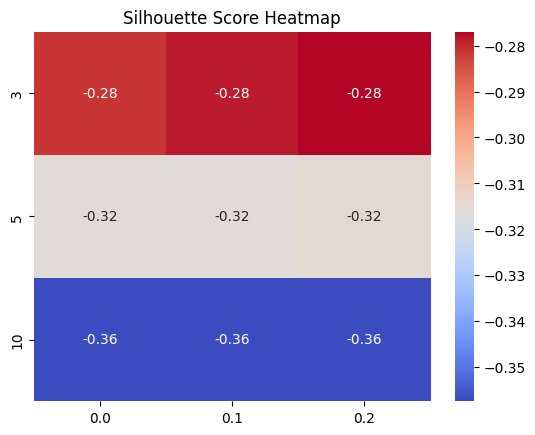

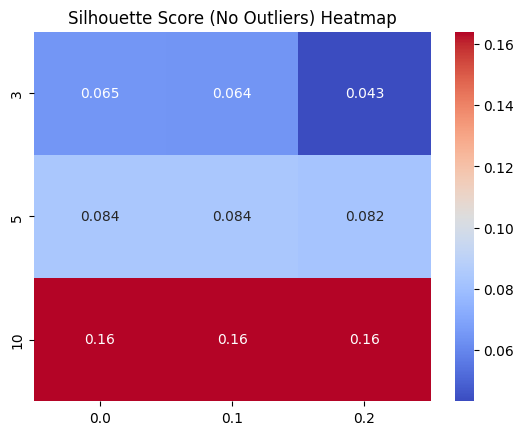

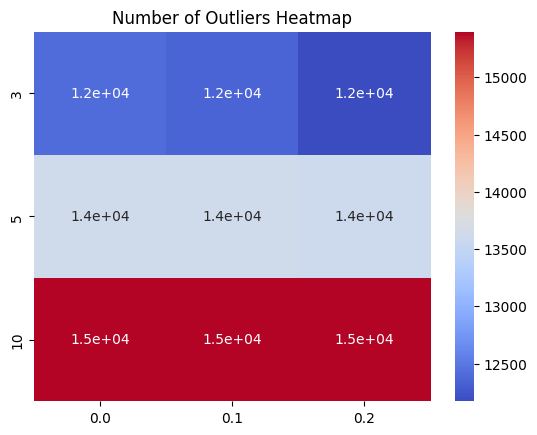

In [ ]:
hdbscan_results = []

min_cluster_sizes = [3, 5, 10]
cluster_selection_epsilons = [0.0, 0.1, 0.2]

score_No_Outliers = []
score=[]
number_of_outliers=[]

for cluster_size in min_cluster_sizes:
    scores_temp=[]
    number_of_outliers_temp=[]
    score_No_Outliers_temp=[]
    for epsilon in cluster_selection_epsilons:
        hdbscan = HDBSCAN(
            min_cluster_size=cluster_size,
            cluster_selection_epsilon=epsilon,
            metric='cosine',
            cluster_selection_method='leaf',
            )
        hdbscan_results=hdbscan.fit(X)

        # compute silhouette score only of clustered samples (not noise, i.e., not -1)
        mask = hdbscan_results.labels_ != -1

        score_No_Outliers_temp.append(silhouette_score(X[mask], hdbscan_results.labels_[mask]))
        number_of_outliers_temp.append(np.sum(hdbscan_results.labels_ == -1))
        scores_temp.append(silhouette_score(X, hdbscan_results.labels_))
        # print("HDBSCAN parameters:", params)
        # print("Silhouette score:", score)
        # print("Silhouette score (clustered samples only):", score_No_Outliers)
        # print("Number of outliers detected:", np.sum(hdbscan_results.labels_ == -1))
        # print("\n")

    score_No_Outliers.append(score_No_Outliers_temp)
    score.append(scores_temp)
    number_of_outliers.append(number_of_outliers_temp)

#plot the results
score_df = pd.DataFrame(score, index=min_cluster_sizes, columns=cluster_selection_epsilons)
score_No_Outliers_df = pd.DataFrame(score_No_Outliers, index=min_cluster_sizes, columns=cluster_selection_epsilons)
number_of_outliers_df = pd.DataFrame(number_of_outliers, index=min_cluster_sizes, columns=cluster_selection_epsilons)

sns.heatmap(score_df, annot=True, cmap="coolwarm", cbar=True)
plt.title("Silhouette Score Heatmap")
plt.show()

sns.heatmap(score_No_Outliers_df, annot=True, cmap="coolwarm", cbar=True)
plt.title("Silhouette Score (No Outliers) Heatmap")
plt.show()

sns.heatmap(number_of_outliers_df, annot=True, cmap="coolwarm", cbar=True)
plt.title("Number of Outliers Heatmap")
plt.show()

In [ ]:
#train with the best params
hdbscan = HDBSCAN(
    min_cluster_size=3,
    cluster_selection_epsilon=0.0,
    metric='cosine',
    cluster_selection_method='leaf',
)
hdbscan_results=hdbscan.fit(X)

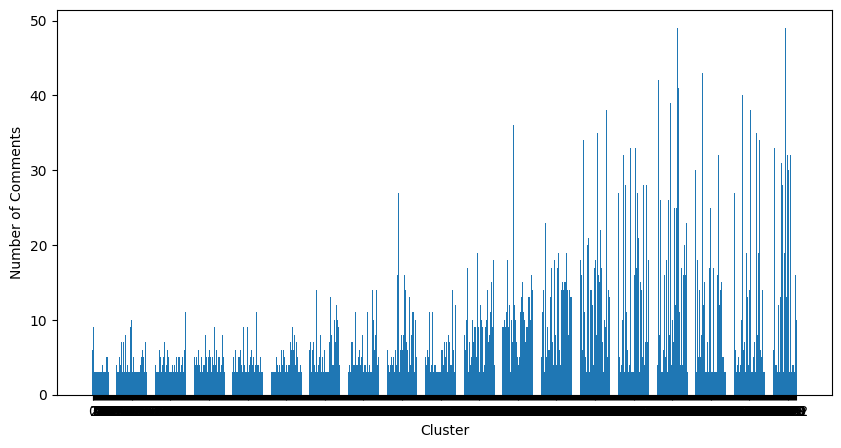

Cluster sizes: cluster
600    49
711    49
612    44
626    43
581    42
       ..
357     3
61      3
4       3
578     3
690     3
Name: count, Length: 723, dtype: int64


In [ ]:
data["cluster"]= hdbscan_results.labels_
data_no_outliers = data[data["cluster"]!=-1]#remove outliers
cluster_sizes = data_no_outliers["cluster"].value_counts()
plt.figure(figsize=(10, 5))
plt.bar(cluster_sizes.index, cluster_sizes.values)
#plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
plt.xlabel("Cluster")
plt.ylabel("Number of Comments")
plt.xticks(cluster_sizes.index)
plt.show()
print("Cluster sizes:", cluster_sizes)

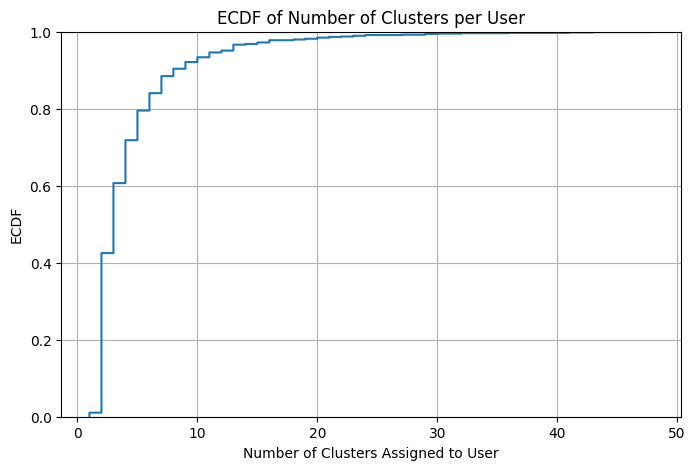

In [ ]:
user_clusters = data_no_outliers.groupby('author')['cluster'].nunique().reset_index()#grouping by author
#user clusters is now a series with author and number of clusters
user_clusters.columns = ['author', 'num_clusters']#turn it into a DF

# Filter user_clusters to only those authors who have multiple comments
authors_with_multiple_comments = data_no_outliers.groupby('author')['body'].nunique()
authors_with_multiple_comments = authors_with_multiple_comments[authors_with_multiple_comments > 1].index
user_clusters = user_clusters[user_clusters['author'].isin(authors_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=user_clusters, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to User')
plt.ylabel('ECDF')
plt.title('ECDF of Number of Clusters per User')
plt.grid(True)
plt.show()

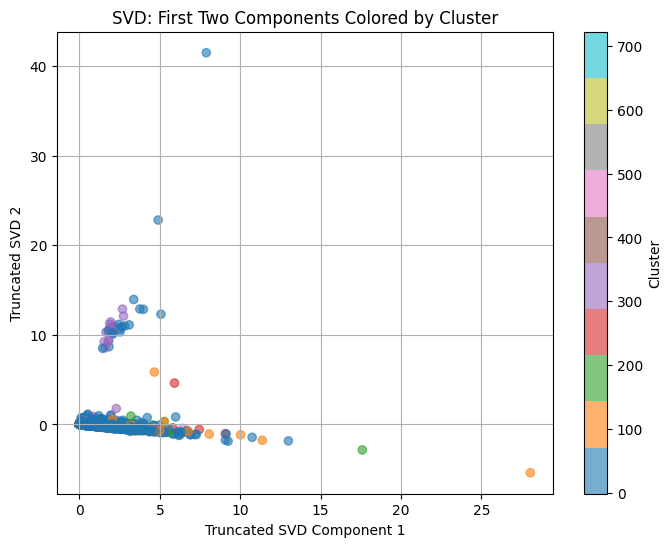

In [ ]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 0], X[:, 1], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 1')
plt.ylabel('Truncated SVD 2')
plt.title('SVD: First Two Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

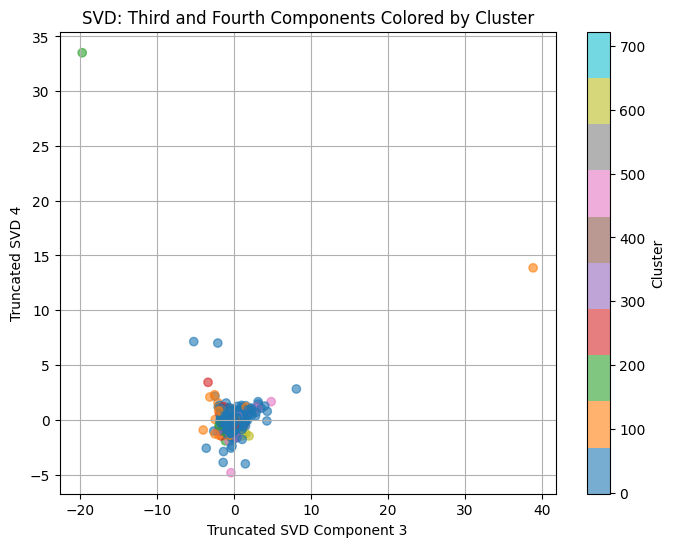

In [ ]:
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X[:, 2], X[:, 3], c=data['cluster'], cmap='tab10', alpha=0.6)
plt.xlabel('Truncated SVD Component 3')
plt.ylabel('Truncated SVD 4')
plt.title('SVD: Third and Fourth Components Colored by Cluster')
plt.colorbar(scatter, label='Cluster')
plt.grid(True)
plt.show()

cluster 600 has 49 comments


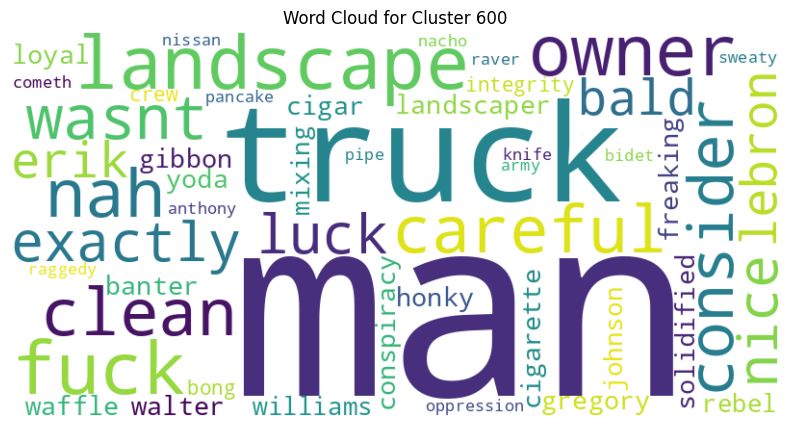

cluster 711 has 49 comments


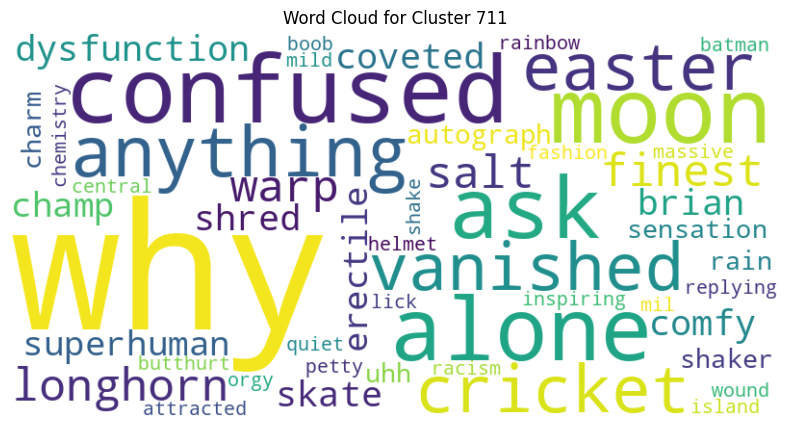

cluster 612 has 44 comments


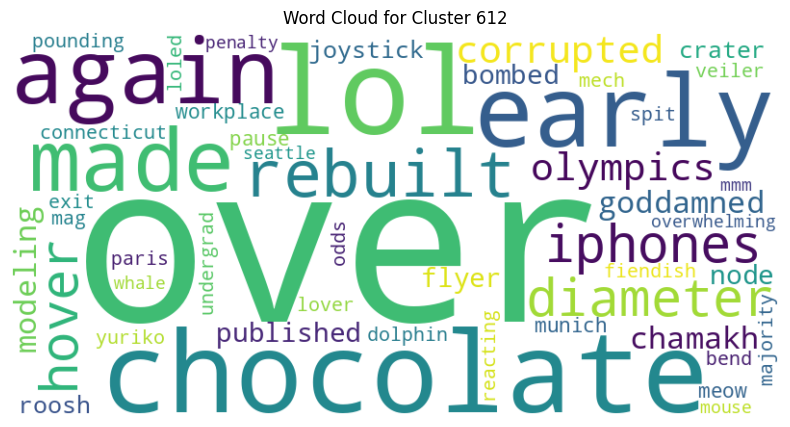

cluster 75 has 3 comments


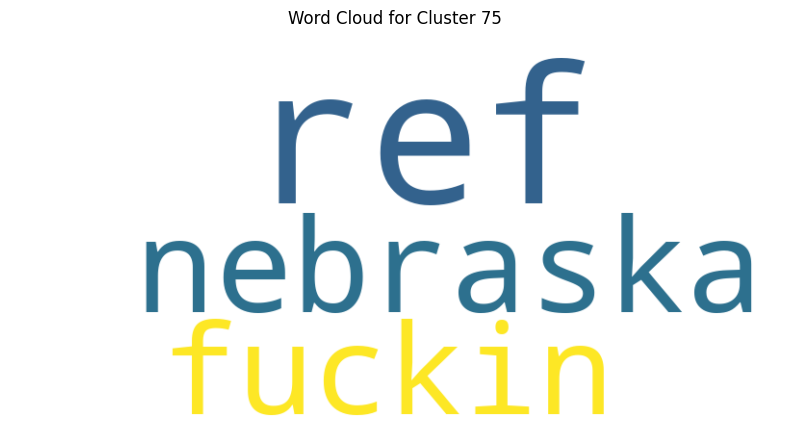

ref nebraska
ref
ref fuckin
cluster 93 has 3 comments


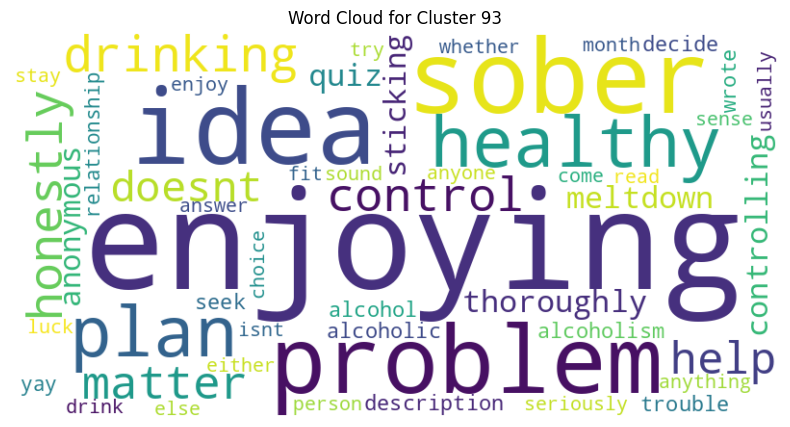

idea come back read sober relationship alcohol doesnt sound healthy wrote description alcoholism lot sense alcoholic either control drinking enjoy controlling drink isnt enjoying enjoying usually control fit drinking t honestly doesnt matter anyone else problem matter problem person anything try quiz answer honestly anonymous help decide seriously should take problem plan stay sober month very idea whether healthy choice trouble sticking plan idea seek help luck
yay enjoying
enjoying meltdown thoroughly


In [ ]:
#Group by cluster and concatenate all comments in each cluster, then compute TF-IDF to understand important words in each cluster
cluster_documents=data_no_outliers[['body','cluster']].groupby('cluster').agg(' '.join).reset_index()
tfidf_vectorizer = TfidfVectorizer()
tfidf_matrix = tfidf_vectorizer.fit_transform(cluster_documents['body'])
terms = tfidf_vectorizer.get_feature_names_out()

#List the first 3 largest clusters
clusters_to_plot = data_no_outliers['cluster'].value_counts().nlargest(3).index
#add two clusters from the smallest
clusters_to_plot = clusters_to_plot.append(data_no_outliers['cluster'].value_counts().nsmallest(2).index)

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in clusters_to_plot:
    tfidf_scores = tfidf_matrix[cluster_num].toarray().flatten()
    top_indices = np.argsort(tfidf_scores)[-50:]  # Get indices of top 50 words
    top_terms = {terms[i]: tfidf_scores[i] for i in top_indices}

    wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(top_terms)

    print(f"cluster {cluster_num} has {cluster_sizes[cluster_num]} comments")
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Word Cloud for Cluster {cluster_num}')
    plt.show()
    if cluster_sizes[cluster_num]<10:
        for comment in data_no_outliers[data_no_outliers['cluster'] == cluster_num]['body'].values:
            print(comment)


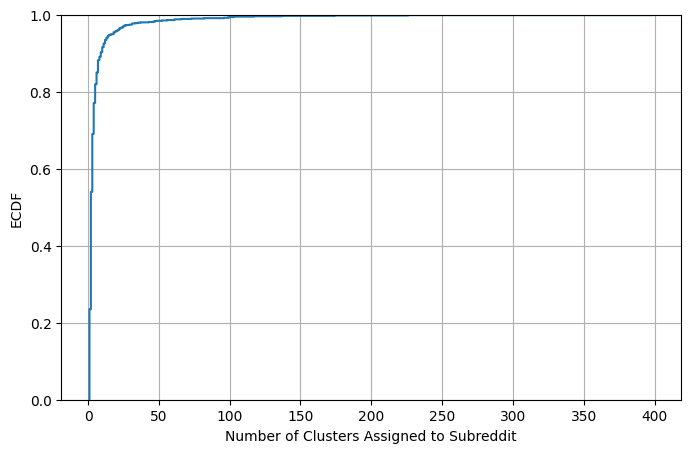

In [ ]:
subreddit_cluster = data.groupby('subreddit')['cluster'].nunique().reset_index()#grouping by subreddit
#subreddit clusters is now a series with subreddit and number of clusters
subreddit_cluster.columns = ['subreddit', 'num_clusters']#turn it into a DF

# Filter subreddit_cluster to only those subreddits that have multiple comments
subreddits_with_multiple_comments = data.groupby('subreddit')['body'].nunique()
subreddits_with_multiple_comments = subreddits_with_multiple_comments[subreddits_with_multiple_comments > 1].index
subreddit_cluster = subreddit_cluster[subreddit_cluster['subreddit'].isin(subreddits_with_multiple_comments)]

plt.figure(figsize=(8, 5))
sns.ecdfplot(data=subreddit_cluster, x='num_clusters')
plt.xlabel('Number of Clusters Assigned to Subreddit')
plt.ylabel('ECDF')
plt.grid(True)
plt.show()

Cluster 600 has 49 comments and 37 subreddits


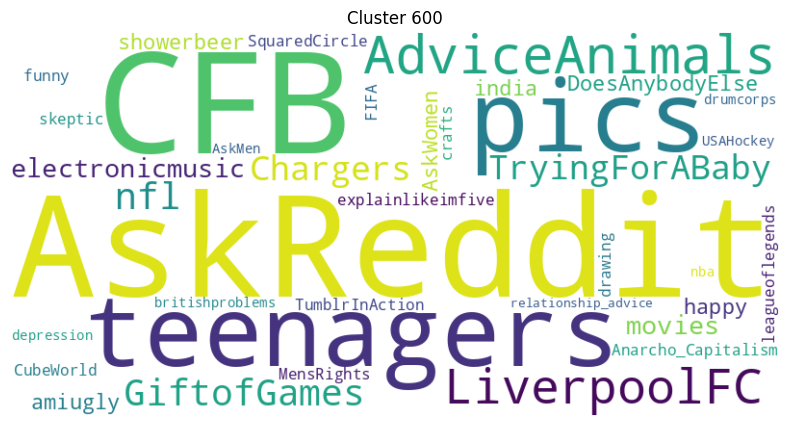

Cluster 711 has 49 comments and 37 subreddits


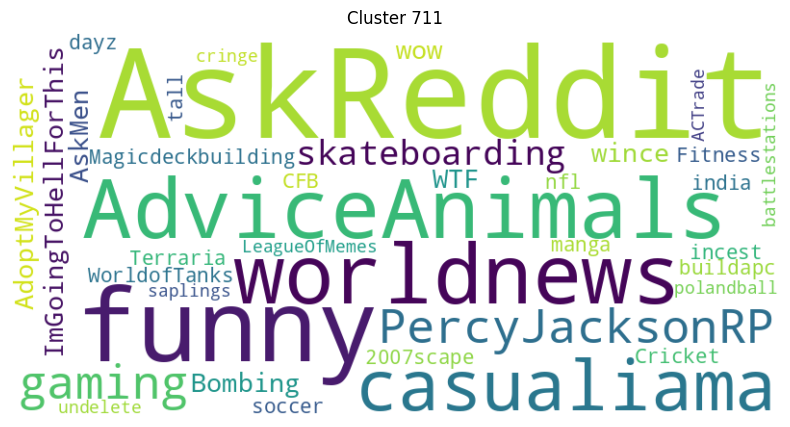

Cluster 612 has 44 comments and 34 subreddits


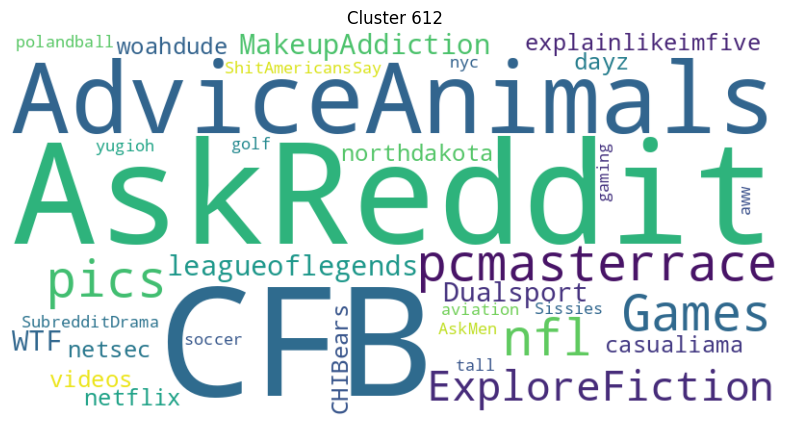

Cluster 75 has 3 comments and 1 subreddits


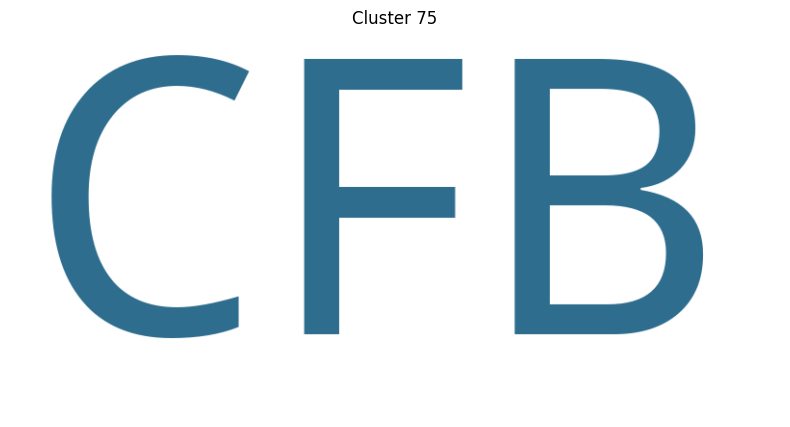

Cluster 93 has 3 comments and 3 subreddits


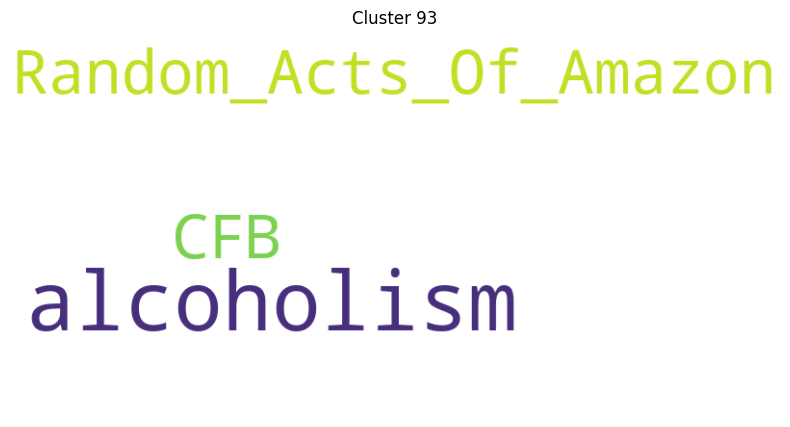

In [ ]:
#List the first 3 largest clusters
clusters_to_plot = data_no_outliers['cluster'].value_counts().nlargest(3).index
#add two clusters from the smallest
clusters_to_plot = clusters_to_plot.append(data_no_outliers['cluster'].value_counts().nsmallest(2).index)

#For each cluster, get the top 50 words by TF-IDF score and plot a word cloud
for cluster_num in clusters_to_plot:
    cluster_sizes = data_no_outliers['cluster'].value_counts()
    subredditsNames = " ".join(data_no_outliers[data_no_outliers['cluster'] == cluster_num]['subreddit'].values)
    wordcloud = WordCloud(width=800, height=400, background_color='white').generate(subredditsNames)

    print(f"Cluster {cluster_num} has {cluster_sizes[cluster_num]} comments and {data_no_outliers[data_no_outliers['cluster'] == cluster_num]['subreddit'].nunique()} subreddits")
    plt.figure(figsize=(10, 5))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')  
    plt.title(f"Cluster {cluster_num}")
    plt.show()

In [ ]:
ari = adjusted_rand_score(data["subreddit"], data["cluster"])
nmi = normalized_mutual_info_score(data["subreddit"], data["cluster"])
ami = adjusted_mutual_info_score(data["subreddit"], data["cluster"])

print("ARI:", ari)
print("NMI:", nmi)
print("AMI:", ami)

ARI: -0.0026940104817695307
NMI: 0.2623176793413616
AMI: 0.00420254845084881
